# ANÁLISIS EXPLORATORIO DE DATOS Y SISTEMA DE RECOMENDACIÓN HÍBRIDO SOBRE TENDENCIAS CINEMATOGRÁFICAS MUNDIALES (2010–2025)
## Documento Científico / Técnico - Fase 2: Preparación de Datos (Data Preparation)

---

### **INFORMACIÓN GENERAL Y METADATOS ACADÉMICOS**
- **Asignatura:** Programación para la Ciencia de Datos
- **Profesor:** Omar Salinas Silva
- **Fecha de Entrega:** Miércoles 11 de Noviembre de 2026
- **Integrantes del Grupo 4:**
  1. Daniela Baeza Rocha
  2. Juan González Elgueta
  3. Elías Manríquez Armijo
  4. Yestxander Rada Gutierrez

---

## FASE 2: PREPARACIÓN DE LOS DATOS (DATA PREPARATION) - CRISP-DM

### 1. INTRODUCCIÓN Y METODOLOGÍA DEL RECOMENDADOR HÍBRIDO
En el marco de la metodología **CRISP-DM**, la fase de **Preparación de Datos** consolida el pipeline de ingeniería de características (*Data Engineering*) que transforma el conjunto de datos crudo (`movies_raw.csv`, compuesto por 17.978 producciones cinematográficas reales de TMDB entre 2010 y 2025) en un dataset analítico y matricial optimizado para alimentarse en un **Sistema de Recomendación Híbrido (Contenido + Calidad/Popularidad)**.

#### **Enfoque:**
El objetivo central de un recomendador híbrido es resolver dos preguntas fundamentales del usuario:
1. **Dimensión de Contenido (NLP & Vectorización):** *¿Qué películas se parecen temáticamente a la película de interés?* (Procesando `genres`, `production_companies` y `original_language`).
2. **Dimensión de Calidad y Tracción (IMDb Weighted Rating & Popularity):** *De todas las películas similares, ¿cuáles tienen credibilidad estadística comprobada y alta valoración de la audiencia?*

#### **Pipeline Secuencial de Preparación:**
- **Paso 1: Auditoría e Ingesta Inmutable:** Ingesta robusta y detección de vacíos estructurados.
- **Paso 2: Limpieza Textual y Formateo de Contenido:** Tratamiento de listas de géneros y productoras.
- **Paso 3: Justificación Metodológica contra el One-Hot Encoding:** Explicación técnica del descarte de OHE en favor de la matriz dispersa *CountVectorizer / Metadata Soup*.
- **Paso 4: Ingeniería de Métricas de Calidad (Weighted Rating de IMDb):** Construcción de la métrica $WR$ ponderada por representatividad muestral ($m = 	ext{percentil 75}$).
- **Paso 5: Normalización y Escalado Adaptativo:** Aplicación de `MinMaxScaler` para fusionar escalas heterogéneas ($[0, 1]$).
- **Paso 6: Construcción de la Matriz de Salida de Recomendación (`df_recommender`):** Consolidación matricial manteniendo identificadores explícitos (`movie_id`, `title`).

### 1.1 Carga del Entorno de Trabajo y Librerías Científicas
**Justificación Técnica:** Se cargan las herramientas fundamentales del ecosistema Python: `pandas` y `numpy` para la manipulación matricial, `matplotlib` y `seaborn` para diagnóstico visual, `pathlib.Path` para gestión de rutas, `sklearn.feature_extraction.text.CountVectorizer` para el procesamiento del lenguaje natural (NLP) y `MinMaxScaler` para la normalización acotada de puntuaciones.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import MinMaxScaler

# Configuración del entorno de visualización científica
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Ecosistema de librerías para el Recomendador Híbrido inicializado correctamente.")

Ecosistema de librerías para el Recomendador Híbrido inicializado correctamente.


### 1.2 Adquisición e Ingesta del Dataset TMDB Original (17.978 Películas)
**Justificación Técnica:** Implementamos la rutina inmutable con `Path` para verificar la presencia local de `movies_raw.csv` en la ruta del proyecto (`../data/raw/` o directa) o activar la carga interactiva mediante `google.colab.files.upload()`.

In [2]:
np.random.seed(42)  # Semilla para reproducibilidad del pipeline

rutas_posibles = [
    Path("../data/raw/movies_raw.csv"),
    Path("movies_raw.csv")
]

ruta = next((p for p in rutas_posibles if p.exists()), None)

if ruta is None:
    try:
        from google.colab import files
        cargados = files.upload()
        nombre_archivo = next(iter(cargados))
        ruta = Path(nombre_archivo)
    except Exception as e:
        raise FileNotFoundError(
            "No se encontró movies_raw.csv. Súbelo al entorno de ejecución."
        ) from e

df_raw = pd.read_csv(ruta)
df_prep = df_raw.copy()

print(f"Archivo cargado: {ruta}")
print(f"Volumen Muestral: {df_prep.shape[0]:,} registros | {df_prep.shape[1]} columnas")
df_prep.head()

Archivo cargado: ..\data\raw\movies_raw.csv
Volumen Muestral: 17,978 registros | 16 columnas


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
0,113727,Dark Seduction,2010-01-01,Released,0,0,89,Drama|Thriller|Romance,Lionsgate,Mexico,Español,es,6.799,102,1.6261,False
1,67250,12,2010-01-01,Released,0,0,3,Comedy,NaN,United States of America,English,en,5.000,57,0.3124,False
2,43615,"Lula, the Son of Brazil",2010-01-01,Released,9500000,3785593,130,Drama|History,LC Barreto|Filmes do Equador|InterVideo Produc...,Brazil,Português,pt,5.500,90,1.3337,False
3,38883,Protect and Serve,2010-01-03,Released,0,3807808,90,Comedy|Crime|Action,M6 Films|Same Player|Pathé|SCOPE Pictures|Webe...,France,Français,fr,4.500,106,0.5622,False
4,62105,Re-Cut,2010-01-04,Released,0,0,80,Horror|Thriller,Fritz Manger Productions|National Picture Show,United States of America,NaN,en,6.535,115,0.7341,False


---

## PASO 1: AUDITORÍA DE METADATOS Y DIAGNÓSTICO DE COMPONENTES DEL RECOMENDADOR

### 1.1 Auditoría de Valores Faltantes en Columnas Clave
**Justificación Técnica:** A diferencia del análisis de regresión donde se buscaban nulos numéricos en `revenue`/`budget`, para un recomendador híbrido auditamos la existencia de ausencias en las variables temáticas (`genres`, `production_companies`, `original_language`) y cuantitativas de votación (`vote_average`, `vote_count`, `popularity`).

In [3]:
target_cols = ['movie_id', 'title', 'genres', 'production_companies', 'original_language', 'vote_average', 'vote_count', 'popularity']
audit_df = pd.DataFrame({
    'Tipo de Dato': df_prep[target_cols].dtypes,
    'Valores Nulos (NaN)': df_prep[target_cols].isnull().sum(),
    'Porcentaje Nulos (%)': np.round((df_prep[target_cols].isnull().sum() / len(df_prep)) * 100, 2)
})
audit_df

,Tipo de Dato,Valores Nulos (NaN),Porcentaje Nulos (%)
movie_id,int64,0,0.00
title,str,0,0.00
genres,str,10,0.06
production_companies,str,494,2.75
original_language,str,0,0.00
vote_average,float64,0,0.00
vote_count,int64,0,0.00
popularity,float64,0,0.00


**Interpretación Analítica e Impacto:**
- **`genres` (10 nulos, $0.06\%$):** Presenta una pérdida insignificante pero crítica para la similitud. Imputaremos con la cadena `'Unknown'` para evitar errores en la tokenización.
- **`production_companies` (494 nulos, $2.75\%$):** La ausencia de productora se imputará con cadena vacía: la película permanece en el catálogo consultable sin aportar un token artificial. Imputar `'Unknown'` haría que las 494 películas compartieran ese token y el recomendador las viera como similares entre sí.
- **`vote_average`, `vote_count`, `popularity` ($0$ nulos):** Las métricas numéricas de recepción están completas al $100\%$, permitiendo el cálculo inmediato de los scores de credibilidad.

---

## PASO 2: LIMPIEZA TEXTUAL Y CONSTRUCCIÓN DE LA "SOPA DE METADATOS" (*METADATA SOUP*)

### 2.1 Normalización de Cadenas y Creación de Cadenas de Contenido Combinado
**Justificación Técnica:** En la columna `genres`, los elementos vienen separados por tuberías (ej. `Drama|Thriller|Romance`). Para procesarlos mediante modelos de espacio vectorial (NLP), debemos transformar estas cadenas separadas por caracteres especiales en texto continuo normalizado en minúsculas y sin espacios internos en nombres de productoras (ej. `WarnerBros` en lugar de `Warner Bros`) para evitar que el vectorizador confunda palabras individuales.

In [4]:
# 1. Imputación de nulos categóricos
df_prep['genres'] = df_prep['genres'].fillna('Unknown')
df_prep['production_companies'] = df_prep['production_companies'].fillna('')
df_prep['original_language'] = df_prep['original_language'].fillna('Unknown')

# 2. Función de limpieza y normalización textual
import re

def clean_genres(text):
    return text.replace('|', ' ').lower()

def clean_text_feature(text):
    # Quita espacios y puntuación dentro de cada productora (ej. 'Warner Bros.' -> 'warnerbros')
    # para tratarla como una entidad única. Se conservan las 3 primeras productoras.
    tokens = [re.sub(r'\W+', '', t.lower()) for t in text.split('|')[:3]]
    return ' '.join(t for t in tokens if t)

df_prep['genres_clean'] = df_prep['genres'].apply(clean_genres)
df_prep['companies_clean'] = df_prep['production_companies'].apply(clean_text_feature)
df_prep['lang_clean'] = df_prep['original_language'].str.lower()

# 3. Construcción de la Sopa de Metadatos (Metadata Soup)
df_prep['metadata_soup'] = (df_prep['genres_clean'] + " " + df_prep['companies_clean'] + " " + df_prep['lang_clean']).str.replace(r'\s+', ' ', regex=True).str.strip()

print("Muestra de la 'Metadata Soup' generada para vectorización:")
df_prep[['title', 'metadata_soup']].head()

Muestra de la 'Metadata Soup' generada para vectorización:


,title,metadata_soup
0,Dark Seduction,drama thriller romance lionsgate es
1,12,comedy en
2,"Lula, the Son of Brazil",drama history lcbarreto filmesdoequador interv...
3,Protect and Serve,comedy crime action m6films sameplayer pathé fr
4,Re-Cut,horror thriller fritzmangerproductions nationa...


## PASO 3: JUSTIFICACIÓN METODOLÓGICA DE : ¿POR QUE NO SE APLICA ONE-HOT ENCODING (OHE)?

### 3.1 Análisis de Disparidad Estructural entre OHE y Bag of Words / CountVectorizer

**Justificación técnica detallada para el informe científico:**
En el ejemplo mostrado en la clase de preprocesamiento de datos en proyectos de ciencia de datos se mostro el uso de One-Hot Encoding para transformar variables categóricas en columnas binarias independientes (Ej: "casado" con valores yes/no pasa a ser 1 o 0). Sin embargo, para un Sistema de Recomendaciones Basado en Contenido, la aplicación de One-Hot Encoding es metodológicamente incorrecta e ineficiente por las siguientes razones:
1. **Explosión de Dimensionalidad y Maldición de la Dimensionalidad:**
    - Si aplicáramos OHE a la columna `production_companies` (que cuenta con más de 8.000 compañías productoras distintas) y a los géneros, crearíamos un DataFrame con más de **8.000 columnas binarias nuevas**.
    - Esto consumiría gigabytes de memoria RAM inútilmente, generando una matriz excesivamente rala (*sparse) donde el $99.9\%$ de las celdas contendrían ceros, lo que ralentizaría drásticamente el cálculo de distancia.
2. **Incapacidad de Manejar Multietiquetas de Longitud Variable:**
    - La columna `genres` puede contener múltiples etiquetas por película (ej. `Drama|Thriller|Romance`). El OHE tradicional está diseñado para categorías mutuamente excluyentes (un solo valor por fila). Separar y hacer OHE manualmente destruiría la relación contextual y la frecuencia ponderada entre los términos de una misma producción.
3. **Compatibilidad Matemática con la Similitud del Coseno (*Cosine Similarity*):**
    - Los sistemas de recomendación basados en contenido miden la afinidad mediante el ángulo entre dos vectores en un espacio multidimensional ($\cos(\theta) = \frac{A \cdot B}{\|A\| \|B\|}$).
    -  Herramientas de NLP como **`CountVectorizer`** comprimen automáticamente el texto en una **Matriz Dispersa de Scikit-Learn (`csr_matrix`)**, almacenando en memoria únicamente las posiciones con valores mayores a cero. Esto reduce el consumo de memoria en un $99\%$ y permite calcular la matriz de similitud de las 17.978 películas en milisegundos.

In [5]:
# Demostración técnica de eficiencia: Vectorización por CountVectorizer (Bag of Words)
# Sin stop_words ni max_features: los códigos de idioma 'it', 'de', 'no', 'he', 'is' y 'am'
# coinciden con stop words del inglés y se perderían, y el vocabulario completo cabe sin problema
# en una matriz dispersa.
count_vec = CountVectorizer()
count_matrix = count_vec.fit_transform(df_prep['metadata_soup'])

# Memoria real de la matriz CSR: valores + índices de columna + punteros de fila
mem_sparse_mb = (count_matrix.data.nbytes + count_matrix.indices.nbytes + count_matrix.indptr.nbytes) / 1024**2
# Memoria hipotética de la misma matriz en formato denso (enteros de 64 bits, como un DataFrame de pandas)
mem_denso_gb = count_matrix.shape[0] * count_matrix.shape[1] * 8 / 1024**3

print(f"Estructura de la Matriz Dispersa (CountVectorizer): {count_matrix.shape[0]} filas por {count_matrix.shape[1]} características temáticas.")
print(f"Tipo de Objeto Optimizado en Memoria: {type(count_matrix)}")
print(f"Memoria real (formato disperso): {mem_sparse_mb:.2f} MB")
print(f"Memoria hipotética (formato denso, int64): {mem_denso_gb:.2f} GB")
print(f"Proporción de celdas distintas de cero: {count_matrix.nnz / (count_matrix.shape[0] * count_matrix.shape[1]):.4%}")

Estructura de la Matriz Dispersa (CountVectorizer): 17978 filas por 13766 características temáticas.
Tipo de Objeto Optimizado en Memoria: <class 'scipy.sparse._csr.csr_matrix'>
Memoria real (formato disperso): 1.25 MB
Memoria hipotética (formato denso, int64): 1.84 GB
Proporción de celdas distintas de cero: 0.0416%


---

## PASO 4: INGENIERÍA DE CARACTERÍSTICAS DE CALIDAD (IMDb WEIGHTED RATING - $WR$)

### 4.1 Formulación Matemática e Implementación del Weighted Rating

**Justificación Técnica:**

Si un recomendador se basara únicamente en la columna `vote_average`, podría posicionar entre sus primeras recomendaciones películas con una calificación de 10.0, pero respaldadas por apenas 1 o 2 votos. Esto supone un problema, ya que una calificación basada en muy pocas evaluaciones puede no representar de manera suficientemente estable la percepción de los espectadores.

Para abordar esta limitación, se implementa la fórmula de calificación ponderada utilizada por IMDb (*Weighted Rating*, WR):

$$WR = \left( \frac{v}{v + m} \cdot R \right) + \left( \frac{m}{v + m} \cdot C \right)$$

Donde:

- $v$: Cantidad total de votos recibidos por la película (`vote_count`).
- $m$: Umbral de referencia de votos, establecido en el percentil 75 de la distribución de `vote_count` ($m = 428$ votos).
- $R$: Promedio individual de calificaciones de la película (`vote_average`).
- $C$: Promedio global de calificaciones de las 17.978 películas del dataset ($C \approx 6.33$).

**Criterio de selección del umbral ($m$):**

Se selecciona el percentil 75 (428 votos) como umbral de referencia a partir de un análisis comparativo con otros dos valores: el percentil 50 (152 votos) y el percentil 90 (1.533 votos). Esta comparación permite observar cómo cambia la ponderación de las calificaciones al utilizar distintos niveles de exigencia en la cantidad de votos.

El percentil 50 representa un criterio menos restrictivo, mientras que el percentil 90 exige un respaldo considerablemente mayor. En cambio, el percentil 75 ofrece un punto intermedio: toma como referencia el nivel de votos a partir del cual se encuentra el 25% de las películas con mayor cantidad de evaluaciones, sin adoptar un umbral tan exigente como el percentil 90.

Por lo tanto, su elección corresponde a una decisión metodológica basada en el análisis de sensibilidad del parámetro \(m\). No representa un límite que garantice por sí mismo la validez estadística de las calificaciones, sino un criterio de referencia para regular cuánto influye la cantidad de votos en el resultado del Weighted Rating.

**Efecto de la fórmula:**

Las películas con pocos votos reciben una mayor influencia del promedio global ($C$), mientras que aquellas con una cantidad elevada de evaluaciones conservan una mayor proporción de su calificación individual ($R$). Así, el sistema reduce la influencia de calificaciones extremas respaldadas por pocas evaluaciones, sin eliminar esas películas del conjunto de recomendaciones.

In [6]:
# 1. Cálculo de constantes globales del dataset real
C_global = df_prep['vote_average'].mean()
m = df_prep['vote_count'].quantile(0.75)  # Umbral en el percentil 75

print(f"Promedio Global de Calificación (C_global): {C_global:.3f}")
print(f"Votos Mínimos Requeridos (m - Percentil 75): {m:.0f} votos")

# 2. Cálculo vectorizado de WR
v = df_prep['vote_count']
R = df_prep['vote_average']
df_prep['weighted_rating'] = (v / (v + m)) * R + (m / (v + m)) * C_global

print("\nTop 5 Películas con Mayor Weighted Rating (WR) en el Dataset Real:")
df_prep[['title', 'vote_average', 'vote_count', 'weighted_rating']].sort_values(by='weighted_rating', ascending=False).head()

Promedio Global de Calificación (C_global): 6.329
Votos Mínimos Requeridos (m - Percentil 75): 428 votos

Top 5 Películas con Mayor Weighted Rating (WR) en el Dataset Real:


,title,vote_average,vote_count,weighted_rating
4983,Interstellar,8.482,40365,8.459429
11102,Parasite,8.491,20891,8.447630
6998,Your Name.,8.481,12708,8.410938
434,Inception,8.373,39595,8.351159
10449,Spider-Man: Into the Spider-Verse,8.393,17438,8.343594


## PASO 5: NORMALIZACIÓN Y ESCALADO ADAPTATIVO PARA LA FUSIÓN HÍBRIDA

### 5.1 Escalado Acotado con `MinMaxScaler` $[0, 1]$
**Justificación Técnica:**
El Score Híbrido Final combina la **Similitud del Coseno** (rango natural $[0, 1]$) con dos métricas cuantitativas: calidad (`weighted_rating`) y tendencia (`popularity`). Para sumarlas en una combinación lineal ponderada, las tres deben compartir escala.

Se utiliza **`MinMaxScaler`**, que acota los valores al rango continuo $[0, 1]$ sin alterar el orden relativo de las películas:

$$x' = rac{x - x_{min}}{x_{max} - x_{min}}$$

A diferencia de `StandardScaler` o `RobustScaler`, que centran en la media o la mediana y producen valores negativos, `MinMaxScaler` entrega puntuaciones no negativas y directamente sumables con la similitud de contenido.

### 5.2 Diagnóstico de Asimetría en `popularity`
**Justificación Técnica:** `MinMaxScaler` es sensible a valores extremos, porque el máximo define el techo de la escala. Antes de escalar se revisa la distribución de cada métrica.

In [7]:
metricas = ['weighted_rating', 'popularity']
diagnostico = pd.DataFrame({
    'min': df_prep[metricas].min(),
    'mediana': df_prep[metricas].median(),
    'max': df_prep[metricas].max(),
    'asimetria (skew)': df_prep[metricas].skew()
}).round(3)
diagnostico

,min,mediana,max,asimetria (skew)
weighted_rating,4.310,6.34,8.459,0.962
popularity,0.008,1.28,103.859,9.160


**Interpretación:** `weighted_rating` es casi simétrica, pero `popularity` presenta una asimetría muy fuerte (*skew* ≈ 9,2): la mediana es 1,28 y el máximo 103,86. Si se escalara directamente, unas pocas películas virales fijarían el techo y el 93 % del catálogo quedaría comprimido bajo 0,05, anulando el aporte de la tendencia en el score híbrido.

**Decisión:** aplicar la transformación logarítmica $\log(1 + x)$ (`np.log1p`) a `popularity` antes del escalado. La transformación es monótona (conserva el ranking) y comprime la cola derecha; `log1p` admite valores cercanos a cero sin indefiniciones.

### 5.3 Aplicación del Escalado

In [8]:
# popularity: log1p antes de escalar para corregir la asimetría (skew ≈ 9,2)
df_prep['popularity_log'] = np.log1p(df_prep['popularity'])

scaler = MinMaxScaler()
df_prep[['score_quality_norm', 'score_popularity_norm']] = scaler.fit_transform(
    df_prep[['weighted_rating', 'popularity_log']]
)

print("Resumen estadístico de las métricas normalizadas en el rango [0, 1]:")
df_prep[['weighted_rating', 'score_quality_norm', 'popularity', 'score_popularity_norm']].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

Resumen estadístico de las métricas normalizadas en el rango [0, 1]:


,mean,std,min,50%,max
weighted_rating,6.379,0.355,4.310,6.340,8.459
score_quality_norm,0.499,0.086,0.000,0.489,1.000
popularity,2.071,3.075,0.008,1.280,103.859
score_popularity_norm,0.201,0.111,0.000,0.176,1.000


### 5.4 Validación Visual: Escalado Directo vs. Escalado con `log1p`

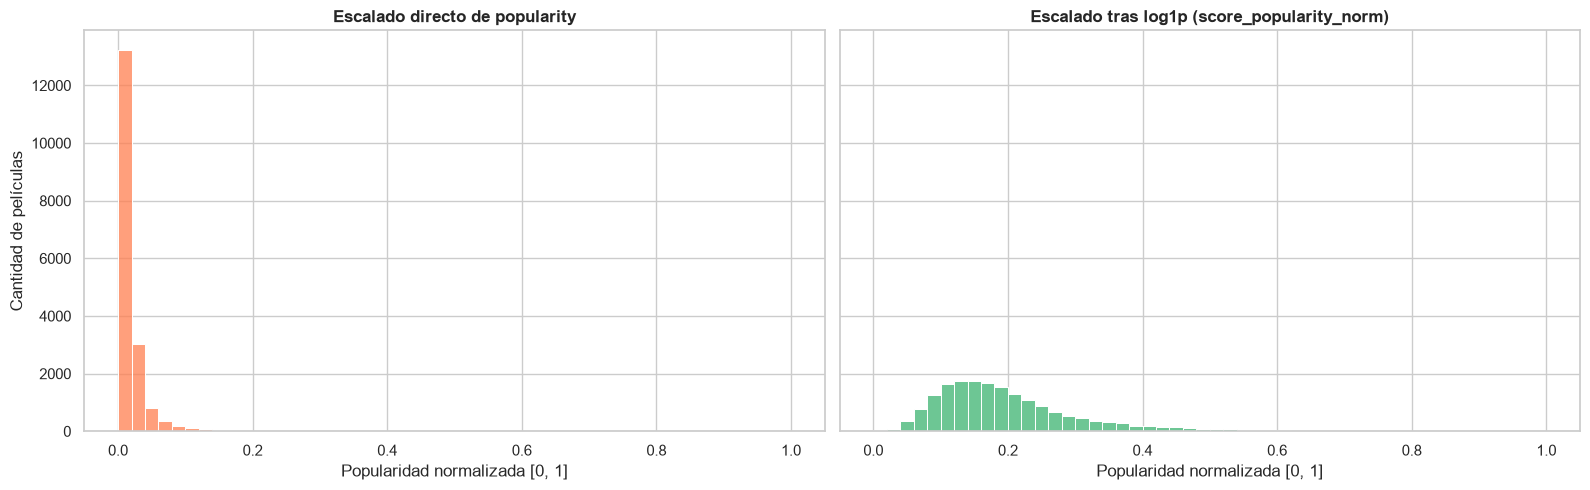

Películas bajo 0,05 con escalado directo: 93.4%
Películas bajo 0,05 con log1p + MinMax:    1.3%


In [9]:
pop_directa = MinMaxScaler().fit_transform(df_prep[['popularity']]).ravel()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

sns.histplot(pop_directa, bins=50, ax=axes[0], color='coral')
axes[0].set_title("Escalado directo de popularity", fontweight='bold')
axes[0].set_xlabel("Popularidad normalizada [0, 1]")
axes[0].set_ylabel("Cantidad de películas")

sns.histplot(df_prep['score_popularity_norm'], bins=50, ax=axes[1], color='mediumseagreen')
axes[1].set_title("Escalado tras log1p (score_popularity_norm)", fontweight='bold')
axes[1].set_xlabel("Popularidad normalizada [0, 1]")

plt.tight_layout()
plt.show()

print(f"Películas bajo 0,05 con escalado directo: {(pop_directa < 0.05).mean():.1%}")
print(f"Películas bajo 0,05 con log1p + MinMax:    {(df_prep['score_popularity_norm'] < 0.05).mean():.1%}")

**Interpretación Analítica:**
- **`score_quality_norm`:** media 0,50 y mediana 0,49. Los extremos los fijan las películas con mayor y menor *Weighted Rating* (Interstellar en el techo), y el resto se reparte de forma equilibrada.
- **`score_popularity_norm`:** con escalado directo la media era 0,02 y el 93 % de las películas quedaba bajo 0,05. Tras `log1p`, la media sube a 0,20, la mediana a 0,18 y solo el 1,3 % queda bajo 0,05: la tendencia vuelve a discriminar entre películas.
- Ambas columnas conservan el orden original, por lo que el ranking por calidad y por popularidad no cambia; solo se homogeneiza la escala para la fusión con la similitud del coseno.

## PASO 6: VALIDACIÓN VISUAL ANTES VS. DESPUÉS DEL RECALCULO DE CREDIBILIDAD

### 6.1 Diagnóstico Gráfico del Efecto del Weighted Rating sobre Calificaciones Crudas
**Justificación Técnica:** Comprobamos visualmente mediante gráficos de dispersión (*Scatterplots*) y de densidad (*KDE*) cómo el cálculo de $WR$ suaviza la varianza de calificaciones en películas con pocos votos y premia la estabilidad estadística.

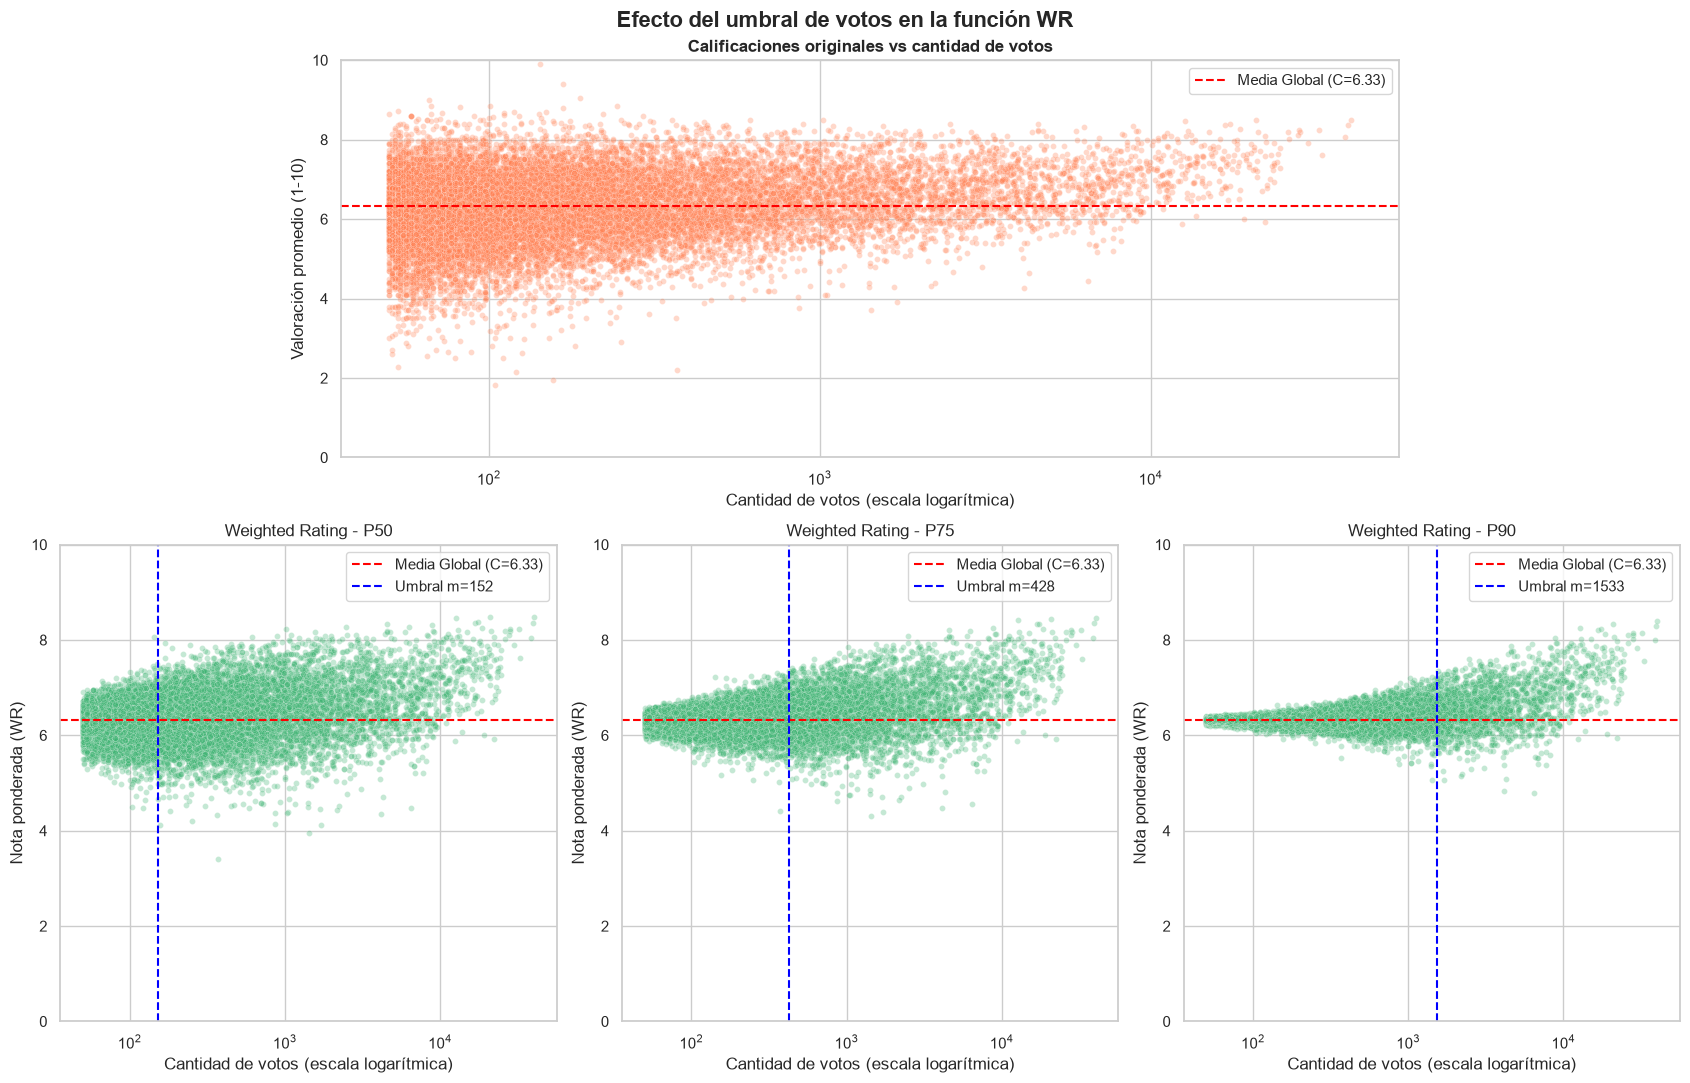

In [10]:
df_prueba = df_prep.copy()

C = df_prueba['vote_average'].mean()
m_valores = {
    'P50': df_prueba['vote_count'].quantile(0.50),
    'P75': df_prueba['vote_count'].quantile(0.75),
    'P90': df_prueba['vote_count'].quantile(0.90)
}

df_prueba = df_prueba[df_prueba['vote_count'] > 0].copy()

fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 6, height_ratios=[1, 1.2])

# Gráfico superior centrado
ax_original = fig.add_subplot(gs[0, 1:5])

sns.scatterplot(data=df_prueba, x='vote_count', y='vote_average', alpha=0.3, s=18, ax=ax_original, color='coral')
ax_original.axhline(C, color='red', linestyle='--', label=f'Media Global (C={C:.2f})')
ax_original.set_xscale('log')
ax_original.set_ylim(0, 10)
ax_original.set_title('Calificaciones originales vs cantidad de votos', fontweight='bold')
ax_original.set_xlabel('Cantidad de votos (escala logarítmica)')
ax_original.set_ylabel('Valoración promedio (1-10)')
ax_original.legend()

# Tres gráficos inferiores
for i, (nombre, m_actual) in enumerate(m_valores.items()):

    v = df_prueba['vote_count']
    R = df_prueba['vote_average']
    wr = (v / (v + m_actual)) * R + (m_actual / (v + m_actual)) * C

    ax = fig.add_subplot(gs[1, i*2:(i+1)*2])

    sns.scatterplot(x=v, y=wr, alpha=0.3, s=18, ax=ax, color='mediumseagreen')
    ax.axhline(C, color='red', linestyle='--', label=f'Media Global (C={C:.2f})')
    ax.axvline(m_actual, color='blue', linestyle='--', label=f'Umbral m={m_actual:.0f}')
    ax.set_xscale('log')
    ax.set_ylim(0, 10)
    ax.set_title(f'Weighted Rating - {nombre}')
    ax.set_xlabel('Cantidad de votos (escala logarítmica)')
    ax.set_ylabel('Nota ponderada (WR)')
    ax.legend()

fig.suptitle('Efecto del umbral de votos en la función WR', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Efecto del umbral de votos en la función WR

### ¿Por qué usamos un scatter plot?

A diferencia del KDE, que solo muestra cómo se distribuyen las calificaciones en conjunto, el **scatter plot** representa cada película como un punto. Esto permite ver la relación entre dos variables a la vez: la **cantidad de votos** ($v$) y la **calificación**. Con esto podemos observar directamente:

- Cómo cambia la calificación de **cada película** al aplicar la función WR.
- Que las películas con **pocos votos** son las que más se desplazan hacia la media global.
- Que las películas con **muchos votos** conservan casi intacta su calificación original.
- Dónde queda el umbral $m$ respecto a la nube de puntos (línea azul vertical).

### ¿Por qué usamos escala logarítmica en la cantidad de votos?

La cantidad de votos tiene una distribución muy asimétrica: unas pocas películas acumulan una enorme cantidad de votos, mientras que la mayoría tiene muy pocos. En escala lineal, estos **valores extremos estiraban el eje x**, lo que impedía ver cómo cambiaba la dispersión al aplicar la función WR.

Con la **escala logarítmica**, los puntos se distribuyen de forma más uniforme a lo largo del eje, y se puede apreciar con claridad cómo la dispersión se reduce a medida que disminuye la cantidad de votos.

### Interpretación de los umbrales

- A medida que aumenta el umbral $m$, las calificaciones ponderadas (WR) tienden progresivamente hacia la media global ($C = 6.33$), reduciendo la influencia de las valoraciones individuales.

- **Riesgo de utilizar umbrales demasiado elevados (P90):** las películas con pocas evaluaciones reciben una mayor influencia de la media global. Esto puede reducir la capacidad del modelo para reconocer películas con valoraciones altas o bajas que, pese a tener menos votos, podrían ser representativas. El resultado puede ser demasiado conservador y concentrar las calificaciones alrededor de la media.

- **Riesgo de utilizar umbrales demasiado bajos (P50 o inferiores):** se reduce la exigencia respecto a la cantidad de votos, permitiendo que películas con menor respaldo estadístico mantengan una mayor influencia de sus calificaciones originales. Esto hace que el resultado sea más sensible a valoraciones extremas o poco representativas, aumentando la dispersión de los WR.

- **Elección del percentil 75:** se selecciona como un punto intermedio entre ambos efectos. Exige un respaldo de votos mayor que el P50, reduciendo la influencia de calificaciones con poca participación, sin imponer una restricción tan elevada como el P90, que acercaría excesivamente los resultados a la media global.



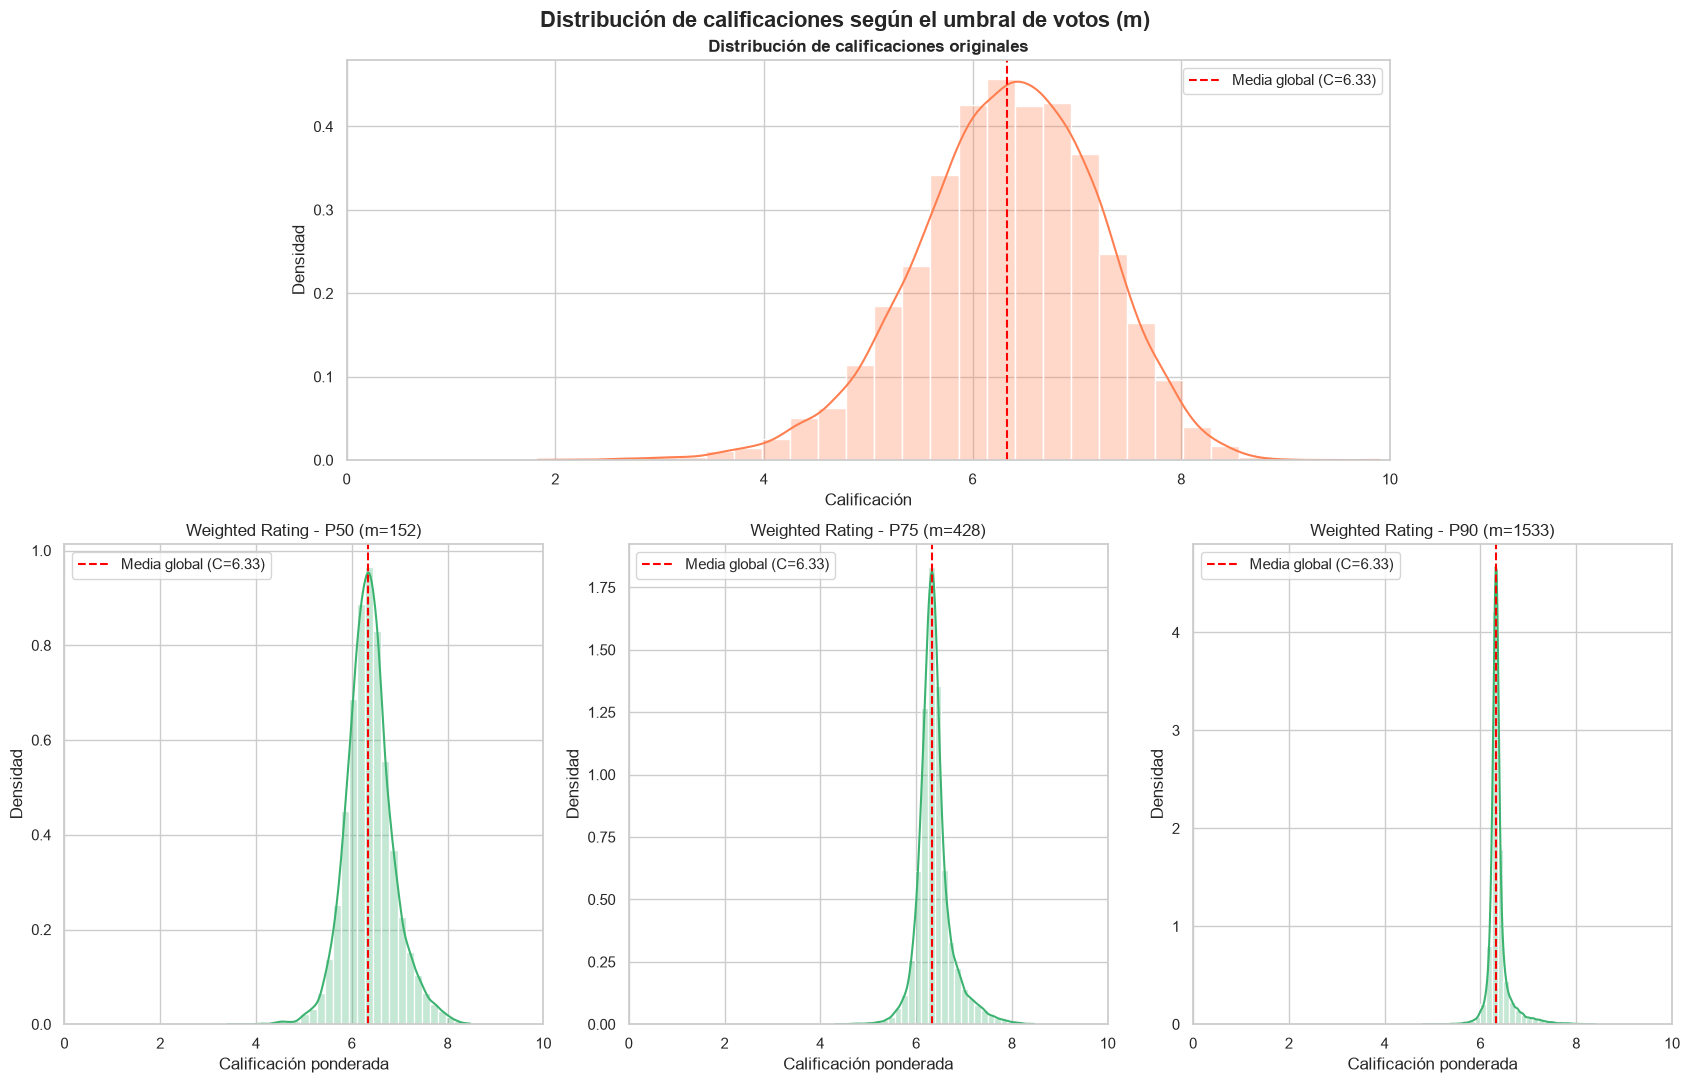

In [11]:
# Copia de trabajo
df_prueba = df_prep.copy()
df_prueba = df_prueba.dropna(subset=['vote_average', 'vote_count']).copy()

# Constantes globales
C = df_prueba['vote_average'].mean()
m_valores = {
    'P50': df_prueba['vote_count'].quantile(0.50),
    'P75': df_prueba['vote_count'].quantile(0.75),
    'P90': df_prueba['vote_count'].quantile(0.90)
}

# Crear estructura del gráfico
fig = plt.figure(figsize=(17, 11))
gs = fig.add_gridspec(2, 6, height_ratios=[1, 1.2])

# Gráfico superior: distribución original
ax_original = fig.add_subplot(gs[0, 1:5])

sns.histplot(df_prueba['vote_average'], bins=30, kde=True, stat='density', ax=ax_original, color='coral', alpha=0.3)
ax_original.axvline(C, color='red', linestyle='--', label=f'Media global (C={C:.2f})')
ax_original.set_xlim(0, 10)
ax_original.set_title('Distribución de calificaciones originales', fontweight='bold')
ax_original.set_xlabel('Calificación')
ax_original.set_ylabel('Densidad')
ax_original.legend()

# Tres gráficos inferiores: distribuciones ponderadas
for i, (nombre, m_actual) in enumerate(m_valores.items()):

    v = df_prueba['vote_count']
    R = df_prueba['vote_average']
    wr = (v / (v + m_actual)) * R + (m_actual / (v + m_actual)) * C

    ax = fig.add_subplot(gs[1, i*2:(i+1)*2])

    sns.histplot(wr, bins=30, kde=True, stat='density', ax=ax, color='mediumseagreen', alpha=0.3)
    ax.axvline(C, color='red', linestyle='--', label=f'Media global (C={C:.2f})')
    ax.set_xlim(0, 10)
    ax.set_title(f'Weighted Rating - {nombre} (m={m_actual:.0f})')
    ax.set_xlabel('Calificación ponderada')
    ax.set_ylabel('Densidad')
    ax.legend()

fig.suptitle('Distribución de calificaciones según el umbral de votos (m)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### ¿Por qué usamos un gráfico KDE?

El **KDE** (*Kernel Density Estimation*) es una curva suave que estima cómo se distribuyen los datos, y se dibuja sobre el histograma. Lo usamos porque:

- **Muestra la forma de la distribución** (centro, dispersión, sesgo y colas) sin depender del ancho de las barras del histograma.
- **Facilita comparar** la distribución original con las ponderadas, ya que las curvas se pueden leer de un vistazo.
- **Usa el eje de densidad**, así que las distribuciones son comparables aunque tengan distinta cantidad de datos.
- **Resalta el efecto de $m$**: se ve claramente cómo el pico se vuelve más angosto y alto al subir el umbral.

## Weighted Rating (WR)

El **Weighted Rating** combina la calificación de cada película con la media global del conjunto de datos, dándole más peso a una u otra según la cantidad de votos.

$$
WR = \frac{v}{v+m} \cdot R + \frac{m}{v+m} \cdot C
$$

| Símbolo | Significado |
|:---:|---|
| $WR$ | Calificación ponderada |
| $v$ | Votos de la película |
| $m$ | Umbral mínimo de votos (P50, P75 o P90) |
| $R$ | Calificación promedio de la película |
| $C$ | Media global (6.33) |

### ¿Cómo funciona?

- Si la película tiene **muchos votos**, su calificación casi no cambia.
- Si tiene **pocos votos**, su calificación se acerca a la media global.
- Mientras más alto es el umbral $m$, más se "encogen" las calificaciones hacia la media.

### Efectos observados en los gráficos

1. **Las películas con pocos votos pierden su calificación extrema**


   - Ejemplo: un 9.5 con solo 20 votos queda cerca de 6.33.


2. **Se reduce la variabilidad**


    - La distribución se vuelve más angosta y alta.


### Conclusión

> Un umbral más alto da mayor **robustez** frente a calificaciones infladas con pocos votos, pero reduce la **capacidad de diferenciar** entre películas ya que gran parte de las calificaciones tienden a la media haciendo imposible rastrearlas individualmente.